<a href="https://colab.research.google.com/github/shambhab31/Interpretable-Student-Performance-Prediction/blob/main/JunProSham.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np

df = pd.read_excel("/content/nprojun.xlsx")

print(df.shape)
print(df.info())
print(df.head())

print(df.isnull().sum())

df.drop("STUDENT ID", axis=1, inplace=True)

df.columns = [col.strip().replace(" ", "_") for col in df.columns]

(145, 33)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145 entries, 0 to 144
Data columns (total 33 columns):
 #   Column                                            Non-Null Count  Dtype 
---  ------                                            --------------  ----- 
 0   STUDENT ID                                        145 non-null    object
 1   Student Age                                       145 non-null    int64 
 2   Sex                                               145 non-null    int64 
 3   Graduated high-school type                        145 non-null    int64 
 4   Scholarship type                                  145 non-null    int64 
 5   Additional work                                   145 non-null    int64 
 6   Regular artistic or sports activity               145 non-null    int64 
 7   Partner                                           145 non-null    int64 
 8   Total salary                                      145 non-null    int64 
 9   Trans to uni          

In [ ]:
df

,Student_Age,Sex,Graduated_high-school_type,Scholarship_type,Additional_work,Regular_artistic_or_sports_activity,Partner,Total_salary,Trans_to_uni,Accom_type,...,Attendance_to_classes,Prep_to_midterm_exams_1,Prep_to_midterm_exams_2,Taking_notes_in_classes,Listening_in_classes,Disc_improves_interest_and_success,Flip_classroom,CGPA_in_last_sem,Expected_GPA_in_grad,COURSE_ID
0,2,2,3,3,1,2,2,1,1,1,...,1,1,1,3,2,1,2,1,1,1
1,2,2,3,3,1,2,2,1,1,1,...,1,1,1,3,2,3,2,2,3,1
2,2,2,2,3,2,2,2,2,4,2,...,1,1,1,2,2,1,1,2,2,1
3,1,1,1,3,1,2,1,2,1,2,...,1,1,2,3,2,2,1,3,2,1
4,2,2,1,3,2,2,1,3,1,4,...,1,2,1,2,2,2,1,2,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
140,2,1,2,3,1,1,2,1,1,2,...,1,1,1,2,1,2,1,3,3,9
141,1,1,2,4,2,2,2,1,4,2,...,2,1,1,3,2,2,1,5,3,9
142,1,1,1,4,2,2,2,1,1,1,...,1,1,1,3,3,2,1,4,3,9
143,2,1,2,4,1,1,1,5,2,3,...,1,2,1,2,1,2,1,5,3,9


In [ ]:
def grade_group(x):
    if x <= 3:
        return 1
    elif x <= 6:
        return 2
    else:
        return 3

df["GRADE_GROUP"] = df["GRADE"].apply(grade_group)

In [ ]:
#Descriptive stats
print(df.describe())

# Grade frequency
print(df["GRADE"].value_counts().sort_index())

       Student_Age         Sex  Graduated_high-school_type  Scholarship_type  \
count   145.000000  145.000000                  145.000000        145.000000   
mean      1.620690    1.600000                    1.944828          3.572414   
std       0.613154    0.491596                    0.537216          0.805750   
min       1.000000    1.000000                    1.000000          1.000000   
25%       1.000000    1.000000                    2.000000          3.000000   
50%       2.000000    2.000000                    2.000000          3.000000   
75%       2.000000    2.000000                    2.000000          4.000000   
max       3.000000    2.000000                    3.000000          5.000000   

       Additional_work  Regular_artistic_or_sports_activity     Partner  \
count       145.000000                           145.000000  145.000000   
mean          1.662069                             1.600000    1.579310   
std           0.474644                             0.4

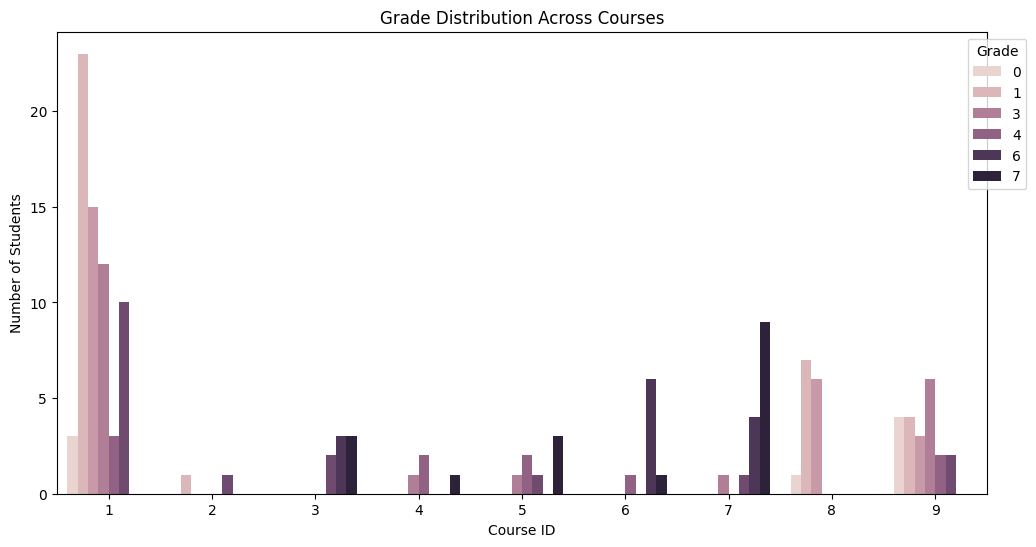

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12,6))
sns.countplot(
    data=df,
    x='COURSE_ID',
    hue='GRADE'
)

plt.title("Grade Distribution Across Courses")
plt.xlabel("Course ID")
plt.ylabel("Number of Students")
plt.legend(title="Grade", bbox_to_anchor=(1.05,1))
plt.show()

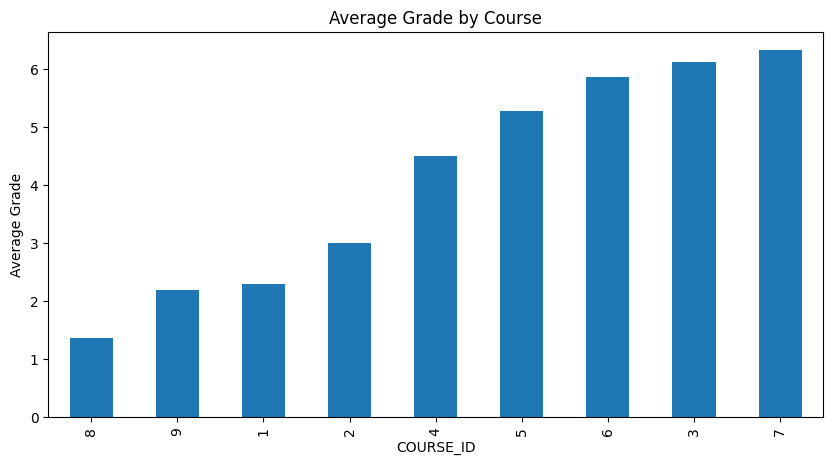

In [ ]:
#Avg grade by course
course_grade = (
    df.groupby("COURSE_ID")["GRADE"]
      .mean()
      .sort_values()
)

plt.figure(figsize=(10,5))

course_grade.plot(kind='bar')

plt.ylabel("Average Grade")
plt.title("Average Grade by Course")
plt.show()

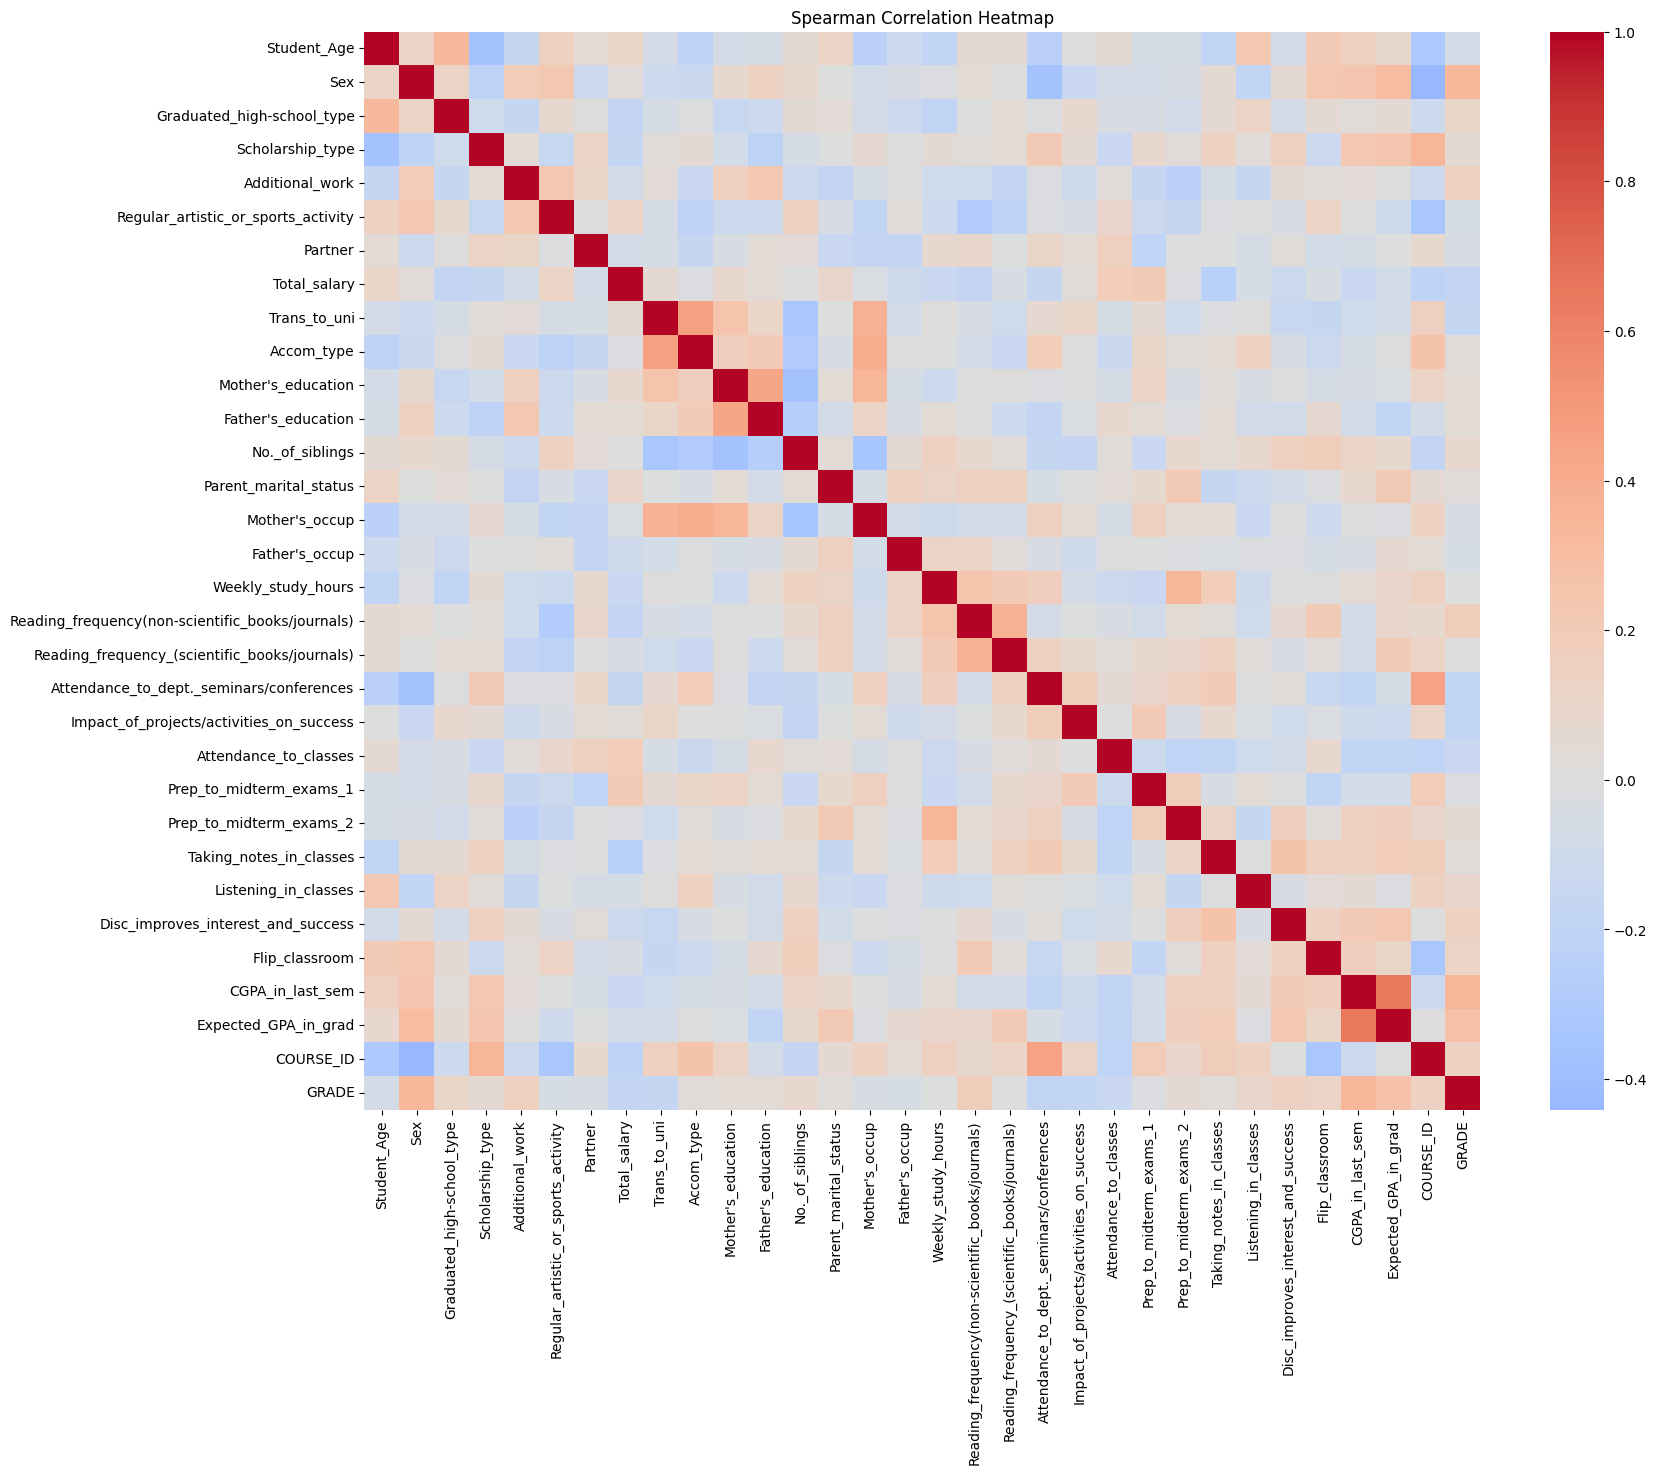

In [ ]:
#Heatmap
import numpy as np

numeric_df = df.select_dtypes(include=np.number)

corr = numeric_df.corr(method='spearman')

plt.figure(figsize=(18,14))

sns.heatmap(
    corr,
    cmap='coolwarm',
    center=0
)

plt.title("Spearman Correlation Heatmap")
plt.show()

In [ ]:
#mutual information ranking
from sklearn.feature_selection import mutual_info_classif

X = df.drop("GRADE", axis=1)
y = df["GRADE"]

mi_scores = mutual_info_classif(
    X,
    y,
    discrete_features=True,
    random_state=42
)

mi_scores = pd.Series(
    mi_scores,
    index=X.columns
).sort_values(ascending=False)

print(mi_scores)

COURSE_ID                                           0.623271
CGPA_in_last_sem                                    0.250852
Mother's_education                                  0.184561
Weekly_study_hours                                  0.152261
Scholarship_type                                    0.142022
Father's_occup                                      0.134495
Expected_GPA_in_grad                                0.127521
Sex                                                 0.120415
Total_salary                                        0.117921
No._of_siblings                                     0.104088
Mother's_occup                                      0.102861
Student_Age                                         0.100847
Father's_education                                  0.097289
Trans_to_uni                                        0.093659
Impact_of_projects/activities_on_success            0.081894
Accom_type                                          0.077654
Reading_frequency(non-sc

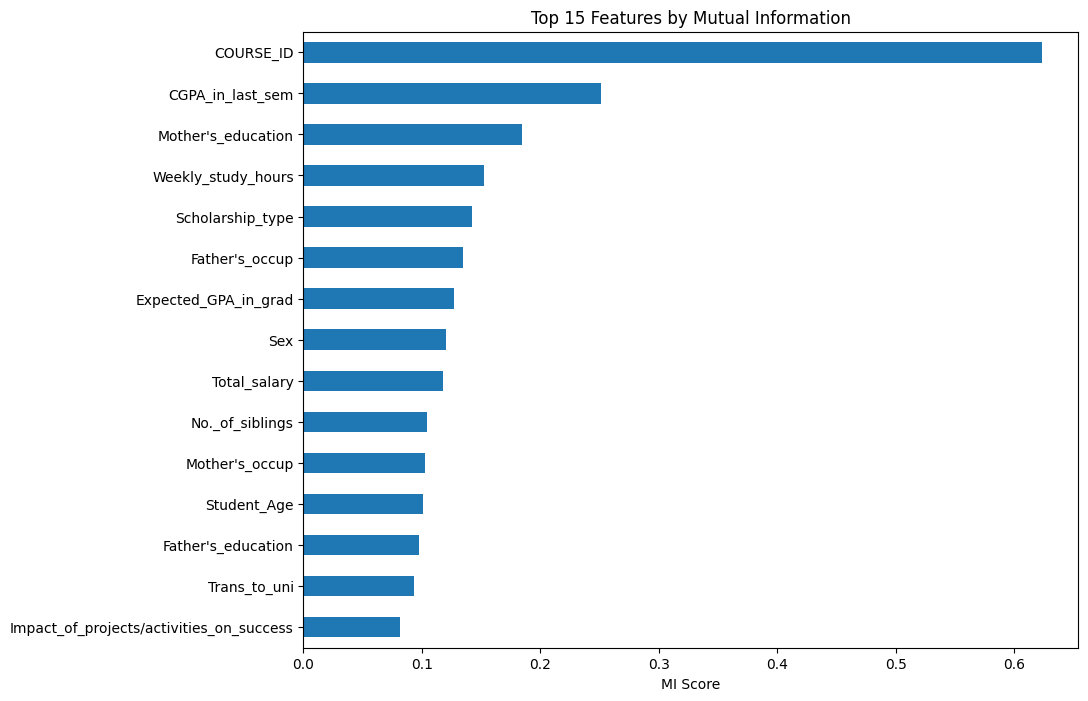

In [ ]:
plt.figure(figsize=(10,8))

mi_scores.head(15).sort_values().plot(kind='barh')

plt.title("Top 15 Features by Mutual Information")
plt.xlabel("MI Score")
plt.show()

In [ ]:
#Feature Engineering

In [ ]:
df["Study_Attendance"] = (
    df["Weekly_study_hours"] *
    df["Attendance_to_classes"]
)

In [ ]:
df["Study_Notes"] = (
    df["Weekly_study_hours"] *
    df["Taking_notes_in_classes"]
)

In [ ]:
df["Class_Participation"] = (
    df["Attendance_to_classes"] *
    df["Listening_in_classes"]
)

In [ ]:
df["Academic_Engagement"] = (
    df["Attendance_to_dept._seminars/conferences"] *
    df["Reading_frequency_(scientific_books/journals)"]
)

In [ ]:
df["Parent_Education"] = (
    df["Mother's_education"] +
    df["Father's_education"]
)

In [ ]:
academic_cols = [
    "Attendance_to_classes",
    "Taking_notes_in_classes",
    "Listening_in_classes",
    "Weekly_study_hours"
]

df["Academic_Behaviour"] = df[academic_cols].sum(axis=1)

In [ ]:
#Importance of engineered features
engineered = [
    "Study_Attendance",
    "Study_Notes",
    "Class_Participation",
    "Academic_Engagement",
    "Parent_Education",
    "Academic_Behaviour"
]

for col in engineered:
    print(
        col,
        df[col].corr(df["GRADE"], method="spearman")
    )

Study_Attendance -0.10260249365189027
Study_Notes 0.020111113901344752
Class_Participation -0.03384111766843426
Academic_Engagement -0.09037488297215303
Parent_Education 0.05619475894009435
Academic_Behaviour -0.0433063983531545


In [ ]:
from sklearn.feature_selection import mutual_info_classif
X = df.drop("GRADE", axis=1)
y = df["GRADE"]

mi_scores = mutual_info_classif(
    X,
    y,
    discrete_features=True,
    random_state=42
)

mi_scores = pd.Series(
    mi_scores,
    index=X.columns
).sort_values(ascending=False)

print(mi_scores)

COURSE_ID                                           0.623271
Academic_Behaviour                                  0.268033
Study_Notes                                         0.252484
CGPA_in_last_sem                                    0.250852
Mother's_education                                  0.184561
Parent_Education                                    0.175298
Study_Attendance                                    0.159445
Weekly_study_hours                                  0.152261
Scholarship_type                                    0.142022
Class_Participation                                 0.137401
Father's_occup                                      0.134495
Academic_Engagement                                 0.127833
Expected_GPA_in_grad                                0.127521
Sex                                                 0.120415
Total_salary                                        0.117921
No._of_siblings                                     0.104088
Mother's_occup          

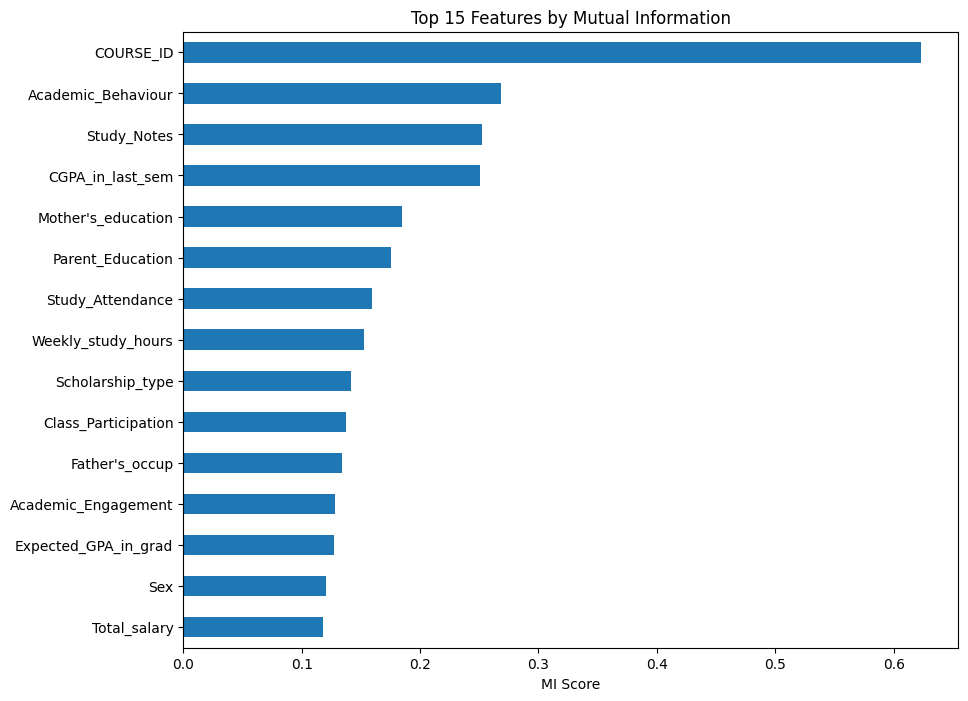

In [ ]:
plt.figure(figsize=(10,8))

mi_scores.head(15).sort_values().plot(kind='barh')

plt.title("Top 15 Features by Mutual Information")
plt.xlabel("MI Score")
plt.show()

In [ ]:
#Examine Class Imbalance

GRADE
0     8
1    35
2    24
3    21
4    10
5    17
6    13
7    17
Name: count, dtype: int64


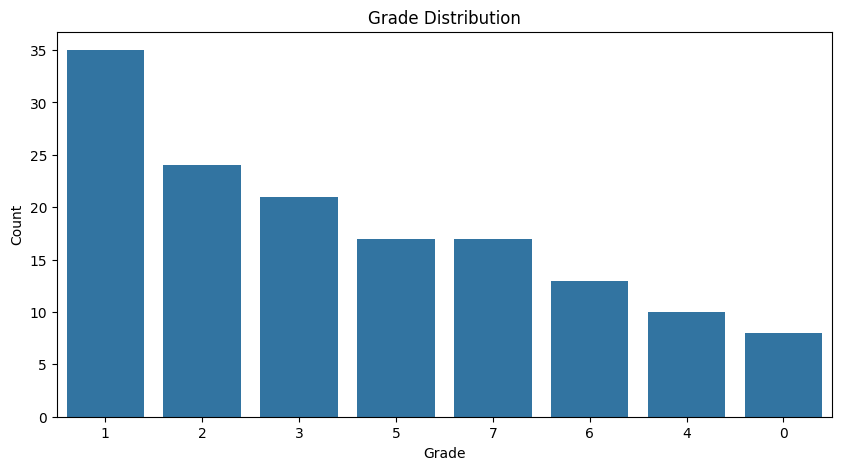

In [ ]:
#grade counts
grade_counts = df["GRADE"].value_counts().sort_index()

print(grade_counts)

import matplotlib.pyplot as plt
import seaborn as sns
#sorted(df["GRADE"].unique())
plt.figure(figsize=(10,5))
decreasing_order = df["GRADE"].value_counts().index
sns.countplot(
    data=df,
    x="GRADE",
    order=decreasing_order
)

plt.title("Grade Distribution")
plt.xlabel("Grade")
plt.ylabel("Count")

plt.show()

In [ ]:
#grade percentages
grade_percent = (
    df["GRADE"]
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

print(round(grade_percent,2))

GRADE
0     5.52
1    24.14
2    16.55
3    14.48
4     6.90
5    11.72
6     8.97
7    11.72
Name: proportion, dtype: float64


In [ ]:
#Imbalance ratio
max_class = grade_counts.max()
min_class = grade_counts.min()

imbalance_ratio = max_class/min_class

print("Imbalance Ratio =", round(imbalance_ratio,2))

Imbalance Ratio = 4.38


In [ ]:
#Imbalance table
imbalance_table = pd.DataFrame({
    "Count": grade_counts,
    "Percentage": round(grade_percent,2)
})

print(imbalance_table)

NameError: name 'grade_percent' is not defined

In [ ]:
#prepping features and target
X = df.drop("GRADE", axis=1)
y = df["GRADE"]

print(X.shape)
print(y.shape)

(145, 37)
(145,)


In [ ]:
#Sratified 5-Fold Cross Validation
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [ ]:
#Feature Scaling
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

In [ ]:
#logistic regression
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

log_model = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(
        max_iter=5000,
        multi_class='multinomial'
    ))
])

log_f1 = cross_val_score(
    log_model,
    X,
    y,
    cv=cv,
    scoring='f1_macro'
)

print("Logistic Regression")
print("Fold Scores:", log_f1)
print("Mean Macro-F1:", log_f1.mean())

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and wi

Logistic Regression
Fold Scores: [0.2202381  0.07916667 0.13571429 0.19771242 0.1839986 ]
Mean Macro-F1: 0.1633660130718954


In [ ]:
#Random Forest classifier
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42
)

rf_f1 = cross_val_score(
    rf_model,
    X,
    y,
    cv=cv,
    scoring='f1_macro'
)

print("Random Forest")
print("Fold Scores:", rf_f1)
print("Mean Macro-F1:", rf_f1.mean())

Random Forest
Fold Scores: [0.25758929 0.32242063 0.25099206 0.10263158 0.27797619]
Mean Macro-F1: 0.2423219507101086


In [ ]:
#SVM
from sklearn.svm import SVC

svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", SVC(
        kernel='rbf'
    ))
])

svm_f1 = cross_val_score(
    svm_model,
    X,
    y,
    cv=cv,
    scoring='f1_macro'
)

print("SVM")
print("Fold Scores:", svm_f1)
print("Mean Macro-F1:", svm_f1.mean())

SVM
Fold Scores: [0.125      0.105      0.0921659  0.09469697 0.07291667]
Mean Macro-F1: 0.09795590699622958


In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import cross_val_score

gb_model = HistGradientBoostingClassifier(
    max_iter=500,
    random_state=42,
)

gb_f1 = cross_val_score(
    gb_model,
    X,
    y,
    cv=cv,
    scoring="f1_macro",
)
print("Gradient Boosting")
print("Fold Scores:", gb_f1)
print("Mean Macro-F1:", gb_f1.mean())

Gradient Boosting
Fold Scores: [0.14912281 0.28667717 0.15347222 0.2593254  0.30555556]
Mean Macro-F1: 0.23083063049781316


In [ ]:
#Compare models
benchmark = pd.DataFrame({
    "Model":[
        "Logistic Regression",
        "Random Forest",
        "Gradient Boosting",
        "SVM"
    ],
    "Mean Macro-F1":[
        log_f1.mean(),
        rf_f1.mean(),
        gb_f1.mean(),
        svm_f1.mean()
    ],
    "Std Dev":[
        log_f1.std(),
        rf_f1.std(),
        gb_f1.std(),
        svm_f1.std()
    ]
})

benchmark = benchmark.sort_values(
    "Mean Macro-F1",
    ascending=False
)

print(benchmark)

                 Model  Mean Macro-F1   Std Dev
1        Random Forest       0.242322  0.074174
2    Gradient Boosting       0.230831  0.066596
0  Logistic Regression       0.163366  0.050386
3                  SVM       0.097956  0.017042


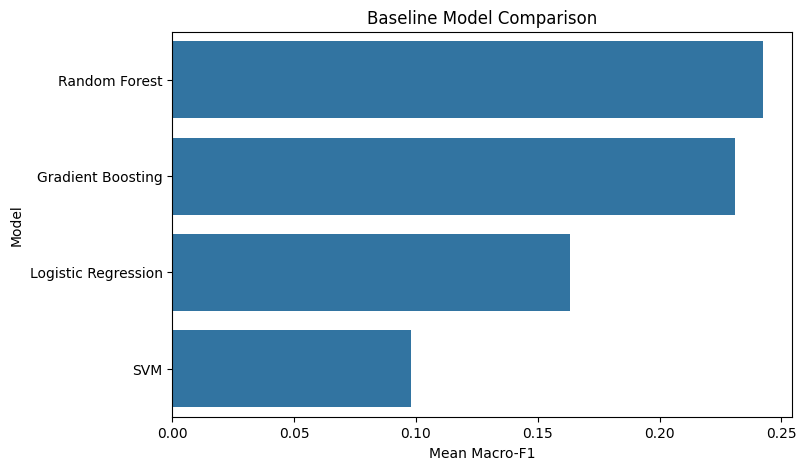

In [ ]:
#Visualization
plt.figure(figsize=(8,5))

sns.barplot(
    data=benchmark,
    x="Mean Macro-F1",
    y="Model"
)

plt.title("Baseline Model Comparison")
plt.show()

In [ ]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report

pred = cross_val_predict(
    rf_model,
    X,
    y,
    cv=cv
)

print(classification_report(y, pred))

              precision    recall  f1-score   support

           0       0.67      0.25      0.36         8
           1       0.28      0.43      0.34        35
           2       0.22      0.25      0.24        24
           3       0.35      0.33      0.34        21
           4       0.00      0.00      0.00        10
           5       0.08      0.06      0.07        17
           6       0.27      0.23      0.25        13
           7       0.50      0.53      0.51        17

    accuracy                           0.30       145
   macro avg       0.30      0.26      0.26       145
weighted avg       0.28      0.30      0.28       145



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


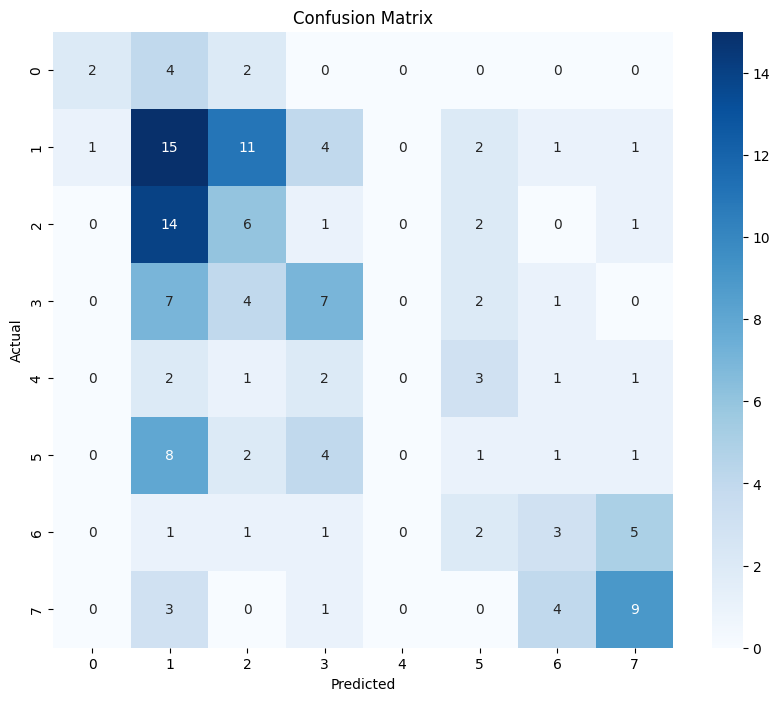

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y, pred)

plt.figure(figsize=(10,8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:
from sklearn.model_selection import RepeatedStratifiedKFold

cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=20,
    random_state=42
)

--- Ordinal Regression Performance ---
Fold Macro-F1 Scores: [0.14748932 0.23344156 0.13116883 0.24351482 0.41918498]
Mean Macro-F1 Score: 0.2349599012099012
Standard Deviation:  0.1024090442356266


Global Classification Report:
              precision    recall  f1-score   support

           0       0.20      0.12      0.15         8
           1       0.47      0.26      0.33        35
           2       0.25      0.38      0.30        24
           3       0.24      0.38      0.30        21
           4       0.08      0.10      0.09        10
           5       0.07      0.06      0.06        17
           6       0.44      0.54      0.48        13
           7       0.44      0.24      0.31        17

    accuracy                           0.28       145
   macro avg       0.27      0.26      0.25       145
weighted avg       0.31      0.28      0.27       145



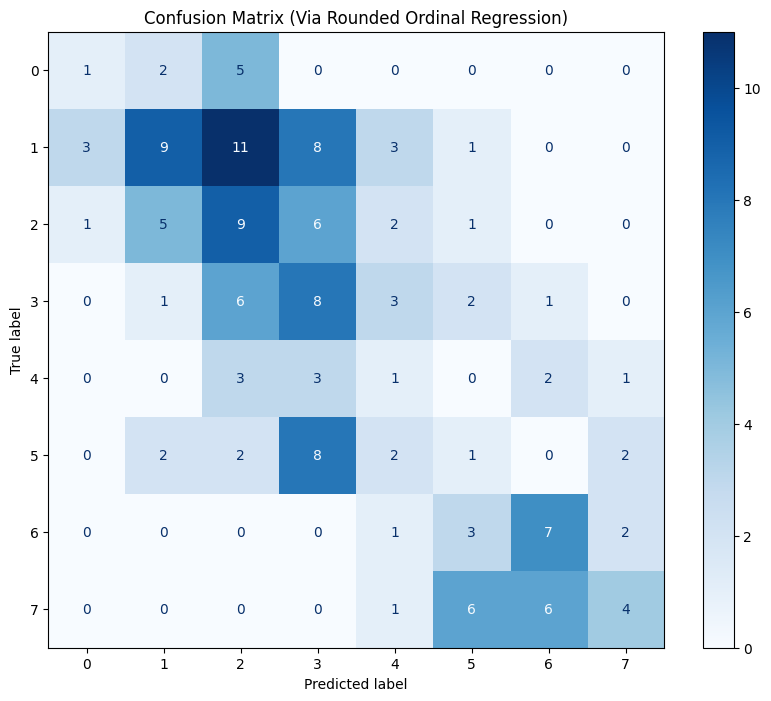

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedKFold

# --- 1. Custom Evaluation Function for Regression ---
def evaluate_regression_as_classification(X, y, cv):
    """
    Trains a regressor using cross-validation, rounds predictions to
    the nearest integer, and prints classification-style metrics.
    """
    # Arrays to store true targets and our rounded predictions across all folds
    all_y_true = []
    all_y_pred_rounded = []
    fold_f1_scores = []

    # Track unique classes dynamically based on your target variable
    unique_classes = sorted(np.unique(y))
    min_class = min(unique_classes)
    max_class = max(unique_classes)

    # Loop through the exact same Stratified K-Fold splits
    for fold, (train_idx, val_idx) in enumerate(cv.split(X, y)):
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

        # Initialize and fit the Regressor
        reg_model = HistGradientBoostingRegressor(max_iter=300, random_state=42)
        reg_model.fit(X_train, y_train)

        # Predict continuous values on the validation set
        y_pred_continuous = reg_model.predict(X_val)

        # Round to nearest integer and clip values to stay within valid grade bounds (0 to 7)
        y_pred_rounded = np.round(y_pred_continuous)
        y_pred_rounded = np.clip(y_pred_rounded, min_class, max_class).astype(int)

        # Store results for global evaluation
        all_y_true.extend(y_val)
        all_y_pred_rounded.extend(y_pred_rounded)

        # Calculate this specific fold's Macro-F1 score
        # Using a classification report dictionary extract to match cross_val_score behavior
        report_dict = classification_report(y_val, y_pred_rounded, output_dict=True, zero_division=0)
        fold_f1_scores.append(report_dict['macro avg']['f1-score'])

    # --- 2. Print Summary Benchmarks ---
    print("--- Ordinal Regression Performance ---")
    print("Fold Macro-F1 Scores:", np.array(fold_f1_scores))
    print("Mean Macro-F1 Score:", np.mean(fold_f1_scores))
    print("Standard Deviation: ", np.std(fold_f1_scores))
    print("\n")

    # --- 3. Display Classification Report ---
    print("Global Classification Report:")
    print(classification_report(all_y_true, all_y_pred_rounded, zero_division=0))

    # --- 4. Plot the New Confusion Matrix ---
    cm = confusion_matrix(all_y_true, all_y_pred_rounded)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=unique_classes)

    fig, ax = plt.subplots(figsize=(10, 8))
    disp.plot(cmap="Blues", ax=ax)
    ax.set_title("Confusion Matrix (Via Rounded Ordinal Regression)")
    plt.show()

# --- 5. Execution Block ---
# (Assumes cv, X, and y are already defined in your current environment)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

evaluate_regression_as_classification(X, y, cv)

In [ ]:
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import f1_score, classification_report
from sklearn.model_selection import cross_val_predict

#X = df.drop("GRADE", axis=1)
y = df["GRADE"]

rf_reg = RandomForestRegressor(
    n_estimators=300,
    random_state=42
)

pred = cross_val_predict(
    rf_reg,
    X_selected,
    y,
    cv=5
)

pred = np.round(pred).astype(int)
pred = np.clip(pred, y.min(), y.max())

macro_f1 = f1_score(y, pred, average='macro', zero_division=0)

print("Ordinal Regression via Random Forest")
print(f"Overall Macro-F1 Score: {macro_f1:.4f}")

Ordinal Regression via Random Forest
Overall Macro-F1 Score: 0.1562


In [ ]:
from sklearn.feature_selection import mutual_info_classif

mi = mutual_info_classif(
    X,
    y,
    discrete_features=True,
    random_state=42
)

mi = pd.Series(mi,index=X.columns)

selected = mi[mi > mi.median()].index

X_selected = X[selected]

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

param_grid = {
    "n_estimators":[200,500,1000],
    "max_depth":[3,5,7,None],
    "min_samples_leaf":[1,2,4,8],
    "max_features":["sqrt","log2"]
}

rf = RandomForestClassifier(
    random_state=42
)

grid = GridSearchCV(
    rf,
    param_grid,
    scoring="f1_macro",
    cv=5,
    n_jobs=-1
)

grid.fit(X,y)

print(grid.best_params_)
print(grid.best_score_)

KeyboardInterrupt: 

In [ ]:
#Catboost
import numpy as np
!pip install catboost
from catboost import CatBoostClassifier
from sklearn.model_selection import cross_val_score

model = CatBoostClassifier(
    verbose=0,
    random_state=42
)

scores = cross_val_score(
    model,
    X,
    y,
    cv=5,
    scoring='f1_macro'
)

print(scores.mean())

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 9.5 MB/s eta 0:00:00
0.18801658486441095


In [ ]:
from sklearn.feature_selection import mutual_info_classif

mi = mutual_info_classif(
    X,
    y,
    discrete_features=True,
    random_state=42
)

mi_scores = pd.Series(mi,index=X.columns)

print(mi_scores.sort_values(ascending=False))

COURSE_ID                                           0.623271
Academic_Behaviour                                  0.268033
Study_Notes                                         0.252484
CGPA_in_last_sem                                    0.250852
Mother's_education                                  0.184561
Parent_Education                                    0.175298
Study_Attendance                                    0.159445
Weekly_study_hours                                  0.152261
Scholarship_type                                    0.142022
Class_Participation                                 0.137401
Father's_occup                                      0.134495
Academic_Engagement                                 0.127833
Expected_GPA_in_grad                                0.127521
Sex                                                 0.120415
Total_salary                                        0.117921
No._of_siblings                                     0.104088
Mother's_occup          

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_predict

rf = RandomForestRegressor(
    n_estimators=500,
    random_state=42
)

pred = cross_val_predict(
    rf,
    X,
    y,
    cv=5
)

pred = np.round(pred)

In [ ]:
from sklearn.metrics import mean_absolute_error

print(mean_absolute_error(y,pred))

1.6896551724137931


In [ ]:
from sklearn.metrics import accuracy_score

accuracy_score(y, pred)

0.21379310344827587

In [ ]:
within_one = np.mean(np.abs(y - pred) <= 1)

print(within_one)

0.503448275862069


In [ ]:
X2 = X.drop(columns=["COURSE_ID"])

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

log_model = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(
        max_iter=5000,
        multi_class='multinomial'
    ))
])

log_f1 = cross_val_score(
    log_model,
    X2,
    y,
    cv=cv,
    scoring='f1_macro'
)

print("Logistic Regression")
print("Fold Scores:", log_f1)
print("Mean Macro-F1:", log_f1.mean())

Logistic Regression
Fold Scores: [0.2047619  0.0968254  0.1        0.29166667 0.20211039]
Mean Macro-F1: 0.17907287157287158


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and wi

In [ ]:
df.drop("GRADE", axis=1, inplace=True)

In [ ]:
df

,Student_Age,Sex,Graduated_high-school_type,Scholarship_type,Additional_work,Regular_artistic_or_sports_activity,Partner,Total_salary,Trans_to_uni,Accom_type,...,Prep_to_midterm_exams_1,Prep_to_midterm_exams_2,Taking_notes_in_classes,Listening_in_classes,Disc_improves_interest_and_success,Flip_classroom,CGPA_in_last_sem,Expected_GPA_in_grad,COURSE_ID,GRADE_GROUP
0,2,2,3,3,1,2,2,1,1,1,...,1,1,3,2,1,2,1,1,1,1
1,2,2,3,3,1,2,2,1,1,1,...,1,1,3,2,3,2,2,3,1,1
2,2,2,2,3,2,2,2,2,4,2,...,1,1,2,2,1,1,2,2,1,1
3,1,1,1,3,1,2,1,2,1,2,...,1,2,3,2,2,1,3,2,1,1
4,2,2,1,3,2,2,1,3,1,4,...,2,1,2,2,2,1,2,2,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
140,2,1,2,3,1,1,2,1,1,2,...,1,1,2,1,2,1,3,3,9,2
141,1,1,2,4,2,2,2,1,4,2,...,1,1,3,2,2,1,5,3,9,2
142,1,1,1,4,2,2,2,1,1,1,...,1,1,3,3,2,1,4,3,9,1
143,2,1,2,4,1,1,1,5,2,3,...,2,1,2,1,2,1,5,3,9,2


In [ ]:
#Class Imbalance
grade_counts = df["GRADE_GROUP"].value_counts().sort_index()

print(grade_counts)

GRADE_GROUP
1    88
2    40
3    17
Name: count, dtype: int64


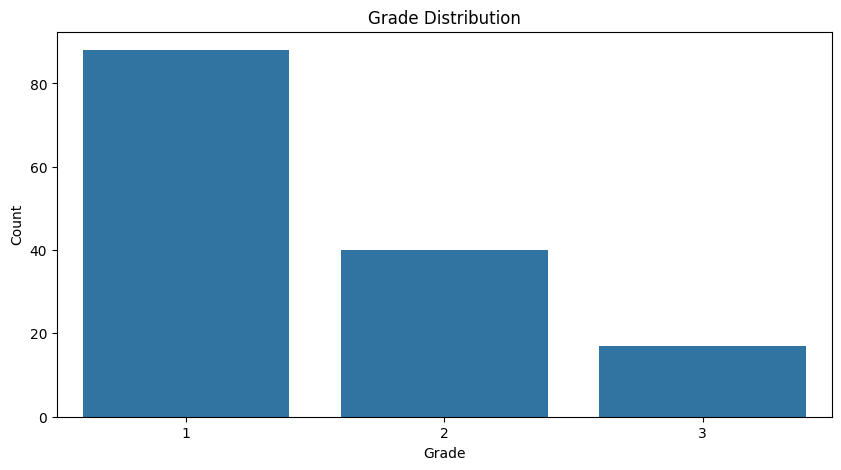

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,5))

sns.countplot(
    data=df,
    x="GRADE_GROUP",
    order=sorted(df["GRADE_GROUP"].unique())
)

plt.title("Grade Distribution")
plt.xlabel("Grade")
plt.ylabel("Count")

plt.show()

In [ ]:
max_class = grade_counts.max()
min_class = grade_counts.min()

imbalance_ratio = max_class/min_class

print("Imbalance Ratio =", round(imbalance_ratio,2))

Imbalance Ratio = 5.18


In [ ]:
X = df.drop(columns=["GRADE_GROUP"])

y = df["GRADE_GROUP"]

In [ ]:
!pip install imbalanced-learn

In [ ]:
#SMOTE
from imblearn.over_sampling import SMOTE

smote = SMOTE(
    sampling_strategy='auto',
    random_state=42,
    k_neighbors=3
)

X_smote, y_smote = smote.fit_resample(X, y)

print("Before SMOTE")
print(y.value_counts())

print("\nAfter SMOTE")
print(y_smote.value_counts())

Before SMOTE
GRADE_GROUP
1    88
2    40
3    17
Name: count, dtype: int64

After SMOTE
GRADE_GROUP
1    88
2    88
3    88
Name: count, dtype: int64


In [ ]:
#RF + 5 fold cv
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rf_pipeline = Pipeline([
    ('smote', SMOTE(
        random_state=42,
        k_neighbors=3
    )),
    ('rf', RandomForestClassifier(
        n_estimators=300,
        random_state=42
    ))
])

scores = cross_val_score(
    rf_pipeline,
    X,
    y,
    cv=cv,
    scoring='f1_macro'
)

print(scores)
print("Mean Macro-F1:", scores.mean())

[0.72026219 0.57619048 0.48821899 0.66924067 0.58986928]
Mean Macro-F1: 0.608756321728458


In [ ]:
#Gradient Boosting + SMOTE
from sklearn.ensemble import HistGradientBoostingClassifier

gb_pipeline = Pipeline([
    ('smote', SMOTE(
        random_state=42,
        k_neighbors=3
    )),
    ('gb', HistGradientBoostingClassifier(
        max_iter=300, class_weight="balanced", random_state=42
    ))
])

scores = cross_val_score(
    gb_pipeline,
    X,
    y,
    cv=cv,
    scoring='f1_macro'
)

print(scores.mean())

0.6409172399678076


In [ ]:
#Logistic Regression + SMOTE
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

lr_pipeline = Pipeline([
    ('smote', SMOTE(
        random_state=42,
        k_neighbors=3
    )),
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression(
        max_iter=5000
    ))
])

scores = cross_val_score(
    lr_pipeline,
    X,
    y,
    cv=cv,
    scoring='f1_macro'
)

print(scores.mean())

0.4634629257644338


In [ ]:
#SVM + SMOTE
from sklearn.svm import SVC

svm_pipeline = Pipeline([
    ('smote', SMOTE(
        random_state=42,
        k_neighbors=3
    )),
    ('scaler', StandardScaler()),
    ('svm', SVC(
        class_weight="balanced",kernel='rbf'
    ))
])

scores = cross_val_score(
    svm_pipeline,
    X,
    y,
    cv=cv,
    scoring='f1_macro'
)

print(scores.mean())

0.4099861684623006


In [ ]:
#Optuna
!pip install lightgbm optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 25.4 MB/s eta 0:00:00


In [ ]:
#objective function
import optuna

from lightgbm import LGBMClassifier

from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_val_score

In [ ]:
def objective(trial):

    params = {
        "objective": "multiclass",
        "num_class": 3,

        "n_estimators": trial.suggest_int(
            "n_estimators",
            100,
            1000
        ),

        "learning_rate": trial.suggest_float(
            "learning_rate",
            0.005,
            0.3,
            log=True
        ),

        "max_depth": trial.suggest_int(
            "max_depth",
            3,
            12
        ),

        "num_leaves": trial.suggest_int(
            "num_leaves",
            10,
            100
        ),

        "min_child_samples": trial.suggest_int(
            "min_child_samples",
            5,
            40
        ),

        "subsample": trial.suggest_float(
            "subsample",
            0.5,
            1.0
        ),

        "colsample_bytree": trial.suggest_float(
            "colsample_bytree",
            0.5,
            1.0
        ),

        "reg_alpha": trial.suggest_float(
            "reg_alpha",
            1e-5,
            10,
            log=True
        ),

        "reg_lambda": trial.suggest_float(
            "reg_lambda",
            1e-5,
            10,
            log=True
        ),

        "random_state": 42,
        "verbosity": -1
    }

    model = LGBMClassifier(**params)

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    score = cross_val_score(
        model,
        X,
        y,
        cv=cv,
        scoring="f1_macro",
        n_jobs=-1
    )

    return score.mean()

In [ ]:
#Run optuna search
study = optuna.create_study(
    direction="maximize"
)

study.optimize(
    objective,
    n_trials=100,
    show_progress_bar=True
)

[I 2026-06-27 06:27:32,740] A new study created in memory with name: no-name-501ffcd2-7733-48b3-92d0-00c761f6abb2


  0%|          | 0/100 [00:00<?, ?it/s]

[I 2026-06-27 06:27:41,904] Trial 0 finished with value: 0.6414468996047942 and parameters: {'n_estimators': 373, 'learning_rate': 0.0133788628237052, 'max_depth': 12, 'num_leaves': 12, 'min_child_samples': 23, 'subsample': 0.7169719075904055, 'colsample_bytree': 0.535836459177384, 'reg_alpha': 0.07681334919024942, 'reg_lambda': 0.07534989415042452}. Best is trial 0 with value: 0.6414468996047942.
[I 2026-06-27 06:27:42,530] Trial 1 finished with value: 0.5717049668269181 and parameters: {'n_estimators': 327, 'learning_rate': 0.009715851925166673, 'max_depth': 5, 'num_leaves': 90, 'min_child_samples': 28, 'subsample': 0.6512609168035157, 'colsample_bytree': 0.836830557792998, 'reg_alpha': 0.0060798267219502366, 'reg_lambda': 0.0024782137429082206}. Best is trial 0 with value: 0.6414468996047942.
[I 2026-06-27 06:27:43,777] Trial 2 finished with value: 0.6356223595371667 and parameters: {'n_estimators': 808, 'learning_rate': 0.08391408169559691, 'max_depth': 8, 'num_leaves': 33, 'min_ch

In [ ]:
print("Best Macro F1:")
print(study.best_value)

print("\nBest Parameters:")
print(study.best_params)

Best Macro F1:
0.7236199893585293

Best Parameters:
{'n_estimators': 929, 'learning_rate': 0.23739158383854828, 'max_depth': 6, 'num_leaves': 19, 'min_child_samples': 8, 'subsample': 0.6824457040014809, 'colsample_bytree': 0.6229483644594889, 'reg_alpha': 0.263193348202066, 'reg_lambda': 0.022898297612378427}


In [ ]:
best_params = study.best_params.copy()

best_params["objective"] = "multiclass"
best_params["num_class"] = 3
best_params["random_state"] = 42

final_model = LGBMClassifier(
    **best_params
)

In [ ]:
#Evaluate using cv
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    final_model,
    X,
    y,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

print("Fold Scores:")
print(scores)

print("\nMean Macro F1:")
print(scores.mean())

print("\nStd:")
print(scores.std())

Fold Scores:
[0.76753247 0.7871345  0.71851852 0.71685972 0.62805474]

Mean Macro F1:
0.7236199893585293

Std:
0.055076024118817596


In [ ]:
#Cross valitdated predictions
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report

pred = cross_val_predict(
    final_model,
    X,
    y,
    cv=cv
)

print(
    classification_report(
        y,
        pred
    )
)

Streaming output truncated to the last 5000 lines.
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further split

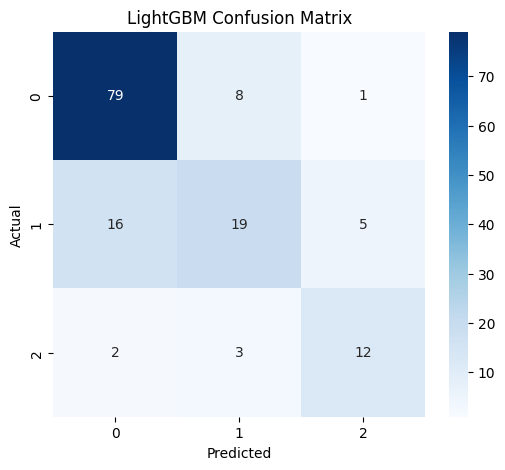

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y, pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("LightGBM Confusion Matrix")

plt.show()

In [ ]:
#feature importance
final_model.fit(X, y)

importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": final_model.feature_importances_
})

importance = importance.sort_values(
    "Importance",
    ascending=False
)

print(importance.head(15))

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000120 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 143
[LightGBM] [Info] Number of data points in the train set: 145, number of used features: 31
[LightGBM] [Info] Start training from score -0.499397
[LightGBM] [Info] Start training from score -1.287854
[LightGBM] [Info] Start training from score -2.143520
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits

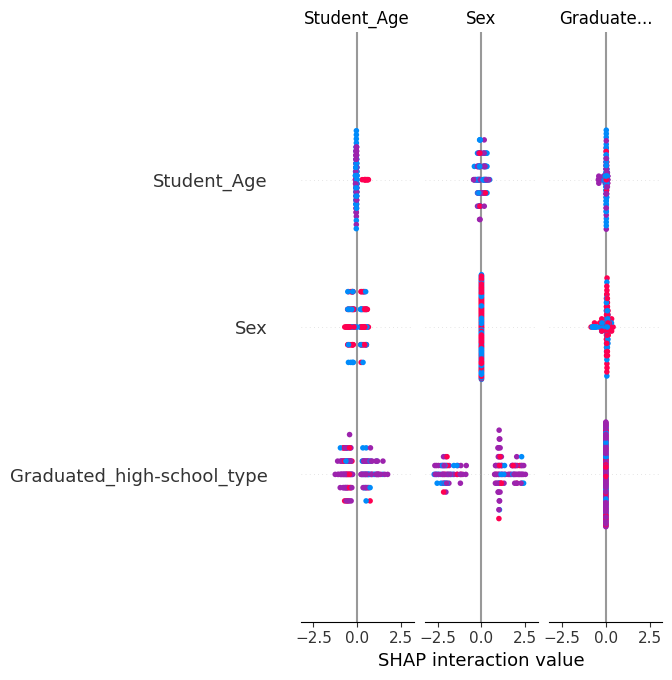

In [ ]:
#SHAP summary plot
import shap
import matplotlib.pyplot as plt

# Initialize SHAP Explainer
explainer = shap.TreeExplainer(final_model)

# Compute SHAP values
shap_values = explainer.shap_values(X)

# Summary plot
shap.summary_plot(
    shap_values,
    X,
    plot_type="dot",
    class_names=["Low", "Medium", "High"]
)

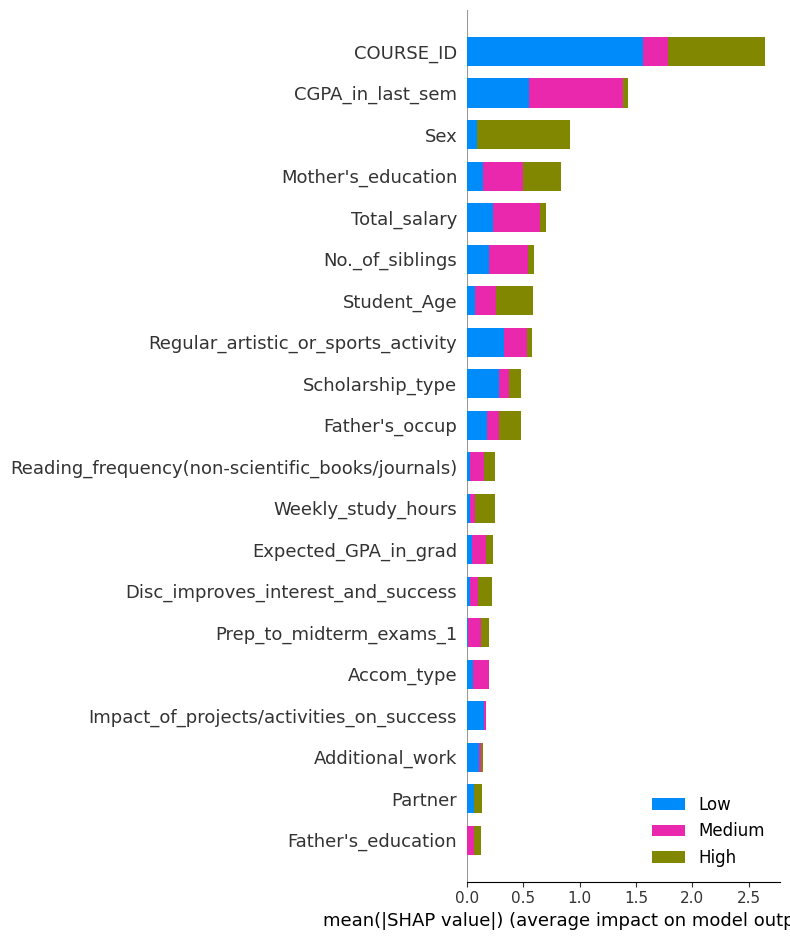

In [ ]:
shap.summary_plot(
    shap_values,
    X,
    plot_type="bar",
    class_names=["Low", "Medium", "High"]
)

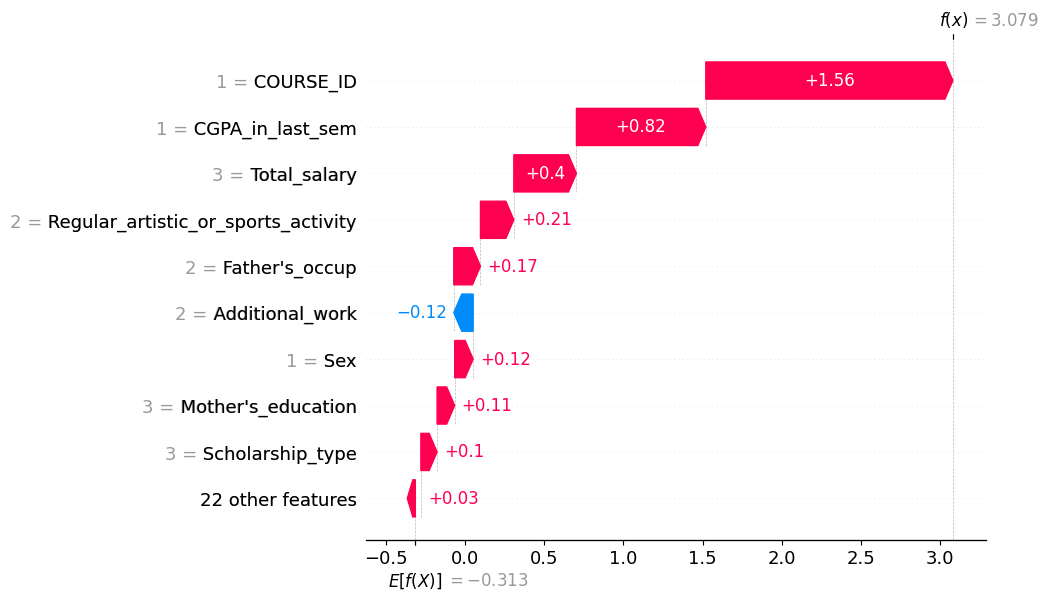

In [ ]:
#Waterfall plot for a particular student
student = 10

explanation = explainer(X.iloc[[student]])

shap.plots.waterfall(
    explanation[0, :, 0]
)

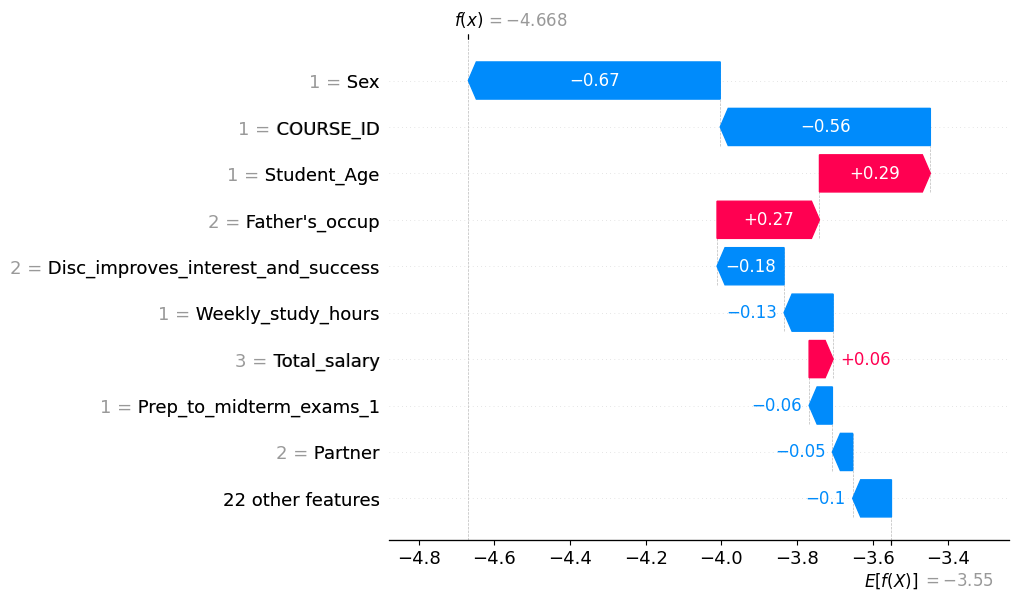

In [ ]:
#same for a different grade
shap.plots.waterfall(
    explanation[0, :, 2]
)

In [ ]:
#LIME Local explanation
!pip install lime
from lime.lime_tabular import LimeTabularExplainer

lime_explainer = LimeTabularExplainer(
    training_data=X.values,
    feature_names=X.columns.tolist(),
    class_names=["Low", "Medium", "High"],
    mode="classification"
)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 10.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283834 sha256=e6b832d617f2ca9247bb74aa04f41e89abd4e9a43c9afd7dd80a6b358cea1fe4
  Stored in directory: /root/.cache/pip/wheels/e7/5d/0e/4b4fff9a47468fed5633211fb3b76d1db43fe806a17fb7486a
Successfully built lime


In [ ]:
student = 10

exp = lime_explainer.explain_instance(
    X.iloc[student].values,
    final_model.predict_proba,
    num_features=10
)
exp.show_in_notebook(show_table=True)

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [ ]:
exp.save_to_file("student10_lime.html")

In [ ]:
explainer = shap.TreeExplainer(final_model)

shap_values = explainer(X)

print(shap_values.shape)

(145, 31, 3)


In [ ]:
student = 10

prediction = final_model.predict(X.iloc[[student]])[0]

print("Predicted class:", prediction)

Predicted class: 1


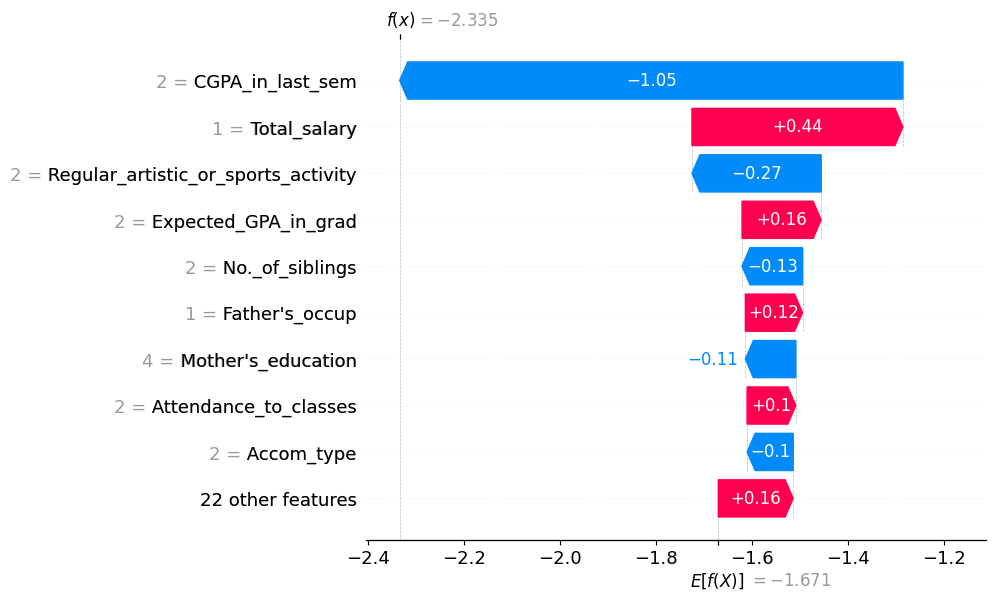

In [ ]:
shap.plots.waterfall(
    shap_values[student, :, prediction-1]
)

In [ ]:
pred = final_model.predict(X)

records = []

for i in range(len(X)):

    cls = pred[i] - 1          # if classes are 1,2,3

    vals = np.abs(shap_values.values[i, :, cls])

    idx = np.argsort(vals)[::-1][:3]

    records.append({
        "Student": i,
        "Prediction": pred[i],
        "Driver1": X.columns[idx[0]],
        "Driver2": X.columns[idx[1]],
        "Driver3": X.columns[idx[2]]
    })

driver_df = pd.DataFrame(records)
print(driver_df)

     Student  Prediction             Driver1  \
0          0           1           COURSE_ID   
1          1           1           COURSE_ID   
2          2           1           COURSE_ID   
3          3           1           COURSE_ID   
4          4           1           COURSE_ID   
..       ...         ...                 ...   
140      140           2  Mother's_education   
141      141           2     No._of_siblings   
142      142           1           COURSE_ID   
143      143           2    CGPA_in_last_sem   
144      144           1    CGPA_in_last_sem   

                                 Driver2                              Driver3  
0                       CGPA_in_last_sem                      No._of_siblings  
1                       CGPA_in_last_sem                      Additional_work  
2                       CGPA_in_last_sem                       Father's_occup  
3                       CGPA_in_last_sem                      Additional_work  
4                      

In [ ]:
#Risk cards
def risk_card(student):

    row = driver_df.iloc[student]

    print("="*60)

    print("Student:", row.Student)

    print("Predicted Grade Group:", row.Prediction)

    print()

    print("Top Factors:")

    print("1.", row.Driver1)

    print("2.", row.Driver2)

    print("3.", row.Driver3)

    print()

    print("Recommended Intervention:")

    if row.Driver1 == "Weekly_study_hours":
        print("- Encourage increased weekly study hours.")

    elif row.Driver1 == "Attendance_to_classes":
        print("- Improve class attendance.")

    elif row.Driver1 == "Taking_notes_in_classes":
        print("- Encourage note-taking during lectures.")

    elif row.Driver1 == "Listening_in_classes":
        print("- Improve classroom engagement.")

    elif row.Driver1 == "CGPA_in_last_sem":
        print("- Provide additional academic mentoring.")

    else:
        print("- Provide personalized academic counselling.")

In [ ]:
risk_card(8)

Student: 8
Predicted Grade Group: 2

Top Factors:
1. CGPA_in_last_sem
2. Mother's_education
3. Regular_artistic_or_sports_activity

Recommended Intervention:
- Provide additional academic mentoring.


In [ ]:
#Cramer's V heatmap
import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency

def cramers_v(x, y):
    confusion_matrix = pd.crosstab(x, y)

    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()

    phi2 = chi2 / n

    r, k = confusion_matrix.shape

    return np.sqrt(phi2 / min(r - 1, k - 1))

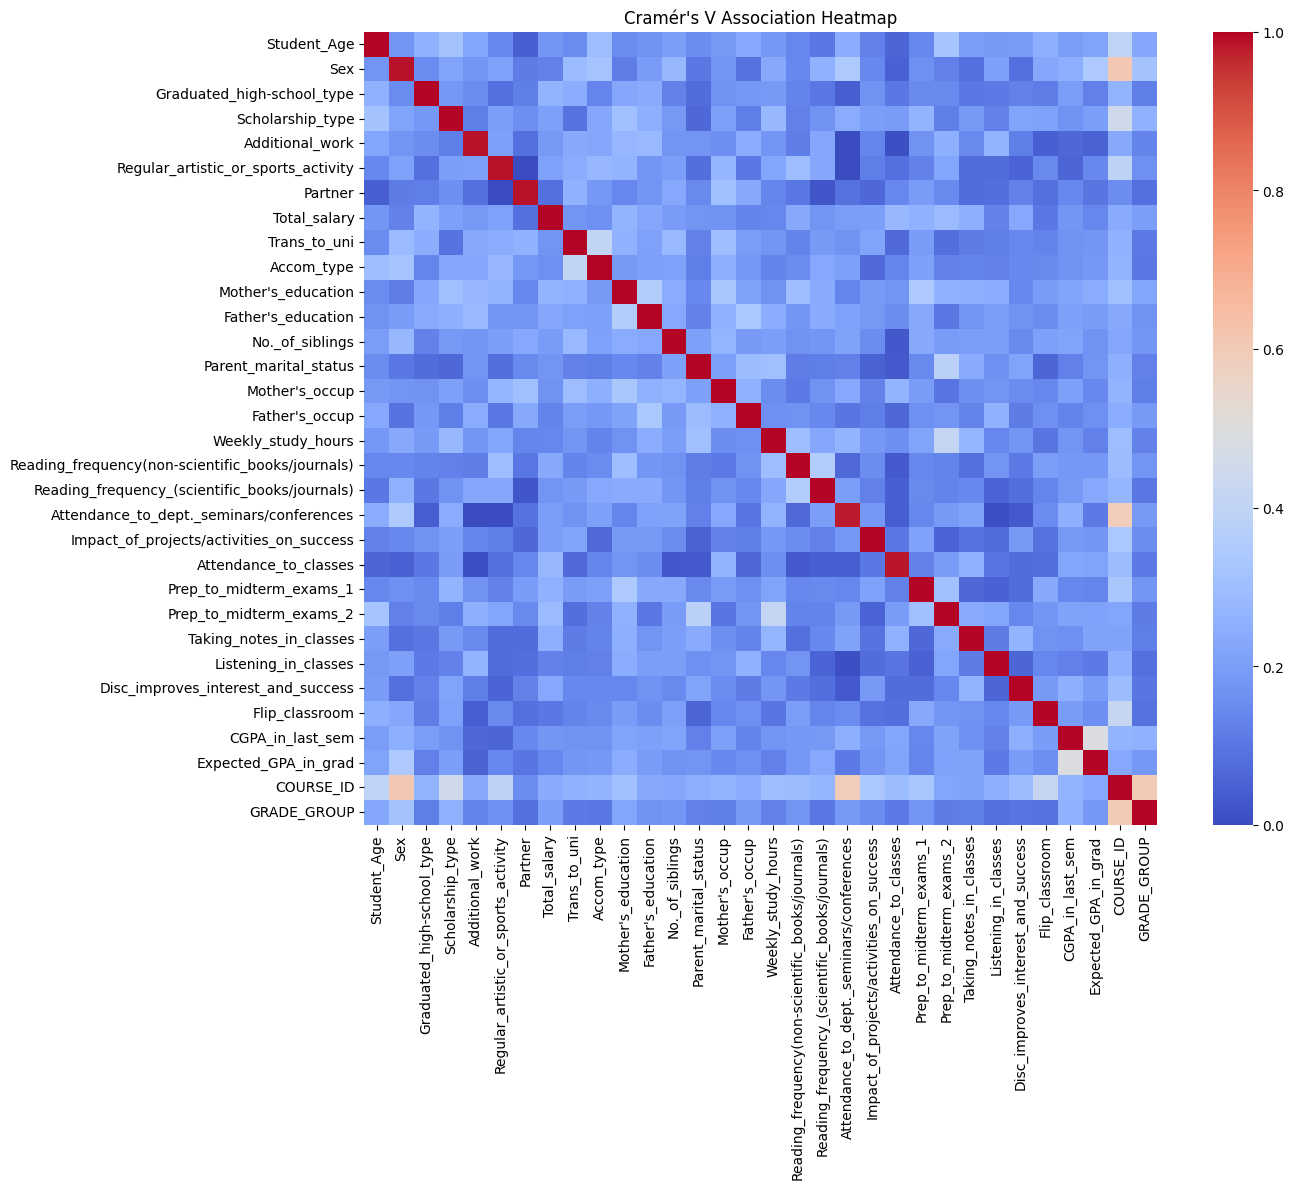

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

cols = df.columns

cramer_matrix = pd.DataFrame(
    np.zeros((len(cols), len(cols))),
    index=cols,
    columns=cols
)

for col1 in cols:
    for col2 in cols:
        cramer_matrix.loc[col1, col2] = cramers_v(
            df[col1],      # <-- one column only
            df[col2]       # <-- one column only
        )

plt.figure(figsize=(15,12))

sns.heatmap(
    cramer_matrix,
    cmap="coolwarm",
    square=True
)

plt.title("Cramér's V Association Heatmap")

plt.tight_layout()
plt.show()

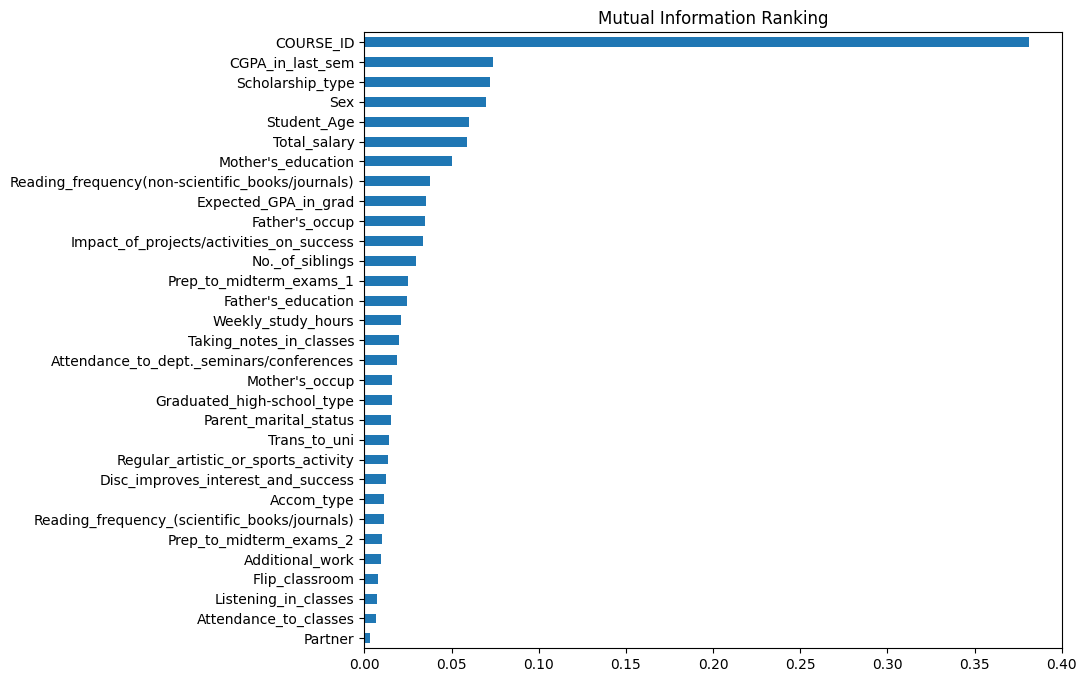

In [ ]:
#Mutual information barplot
mi_scores.sort_values().plot.barh(
    figsize=(9,8)
)

plt.title("Mutual Information Ranking")

plt.show()

In [ ]:
from sklearn.feature_selection import mutual_info_classif

#X = df.drop("GRADE", axis=1)
#y = df["GRADE"]

mi_scores = mutual_info_classif(
    X,
    y,
    discrete_features=True,
    random_state=42
)

mi_scores = pd.Series(
    mi_scores,
    index=X.columns
).sort_values(ascending=False)

print(mi_scores)

COURSE_ID                                           0.381023
CGPA_in_last_sem                                    0.073603
Scholarship_type                                    0.071986
Sex                                                 0.070000
Student_Age                                         0.060017
Total_salary                                        0.059071
Mother's_education                                  0.050487
Reading_frequency(non-scientific_books/journals)    0.037852
Expected_GPA_in_grad                                0.035304
Father's_occup                                      0.034895
Impact_of_projects/activities_on_success            0.033492
No._of_siblings                                     0.029867
Prep_to_midterm_exams_1                             0.025170
Father's_education                                  0.024748
Weekly_study_hours                                  0.021183
Taking_notes_in_classes                             0.019837
Attendance_to_dept._semi

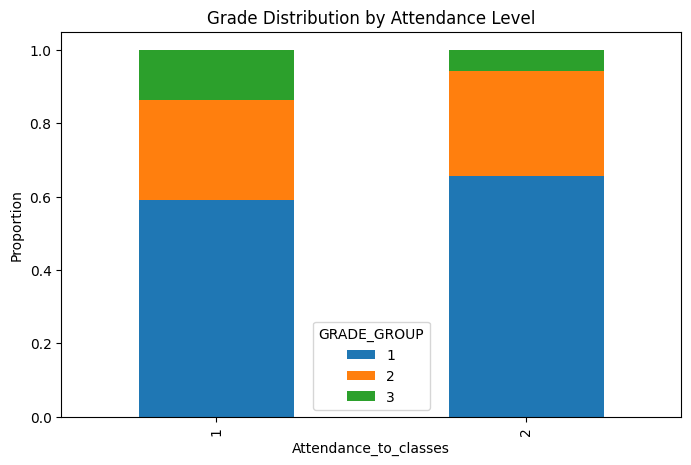

In [ ]:
#Attendance vs Grade Bar Chart
attendance = pd.crosstab(
    df["Attendance_to_classes"],
    df["GRADE_GROUP"],
    normalize="index"
)

attendance.plot(
    kind="bar",
    stacked=True,
    figsize=(8,5)
)

plt.ylabel("Proportion")
plt.title("Grade Distribution by Attendance Level")

plt.show()

/tmp/ipykernel_1268/2896719745.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


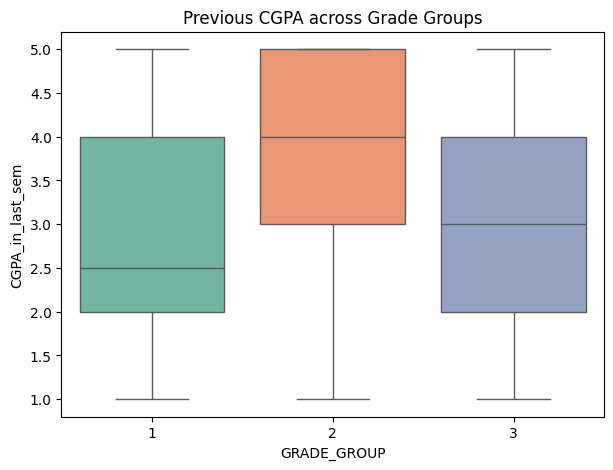

In [ ]:
#Grade vs Previous CGPA boxplot
plt.figure(figsize=(7,5))

sns.boxplot(
    data=df,
    x="GRADE_GROUP",
    y="CGPA_in_last_sem",
    palette="Set2"
)

plt.title("Previous CGPA across Grade Groups")
plt.show()

In [ ]:
#Parallel categories plot
import plotly.express as px

fig = px.parallel_categories(
    df,
    dimensions=[
        "Attendance_to_classes",
        "Weekly_study_hours",
        "Prep_to_midterm_exams_1",
        "GRADE_GROUP"
    ]
)

fig.show()

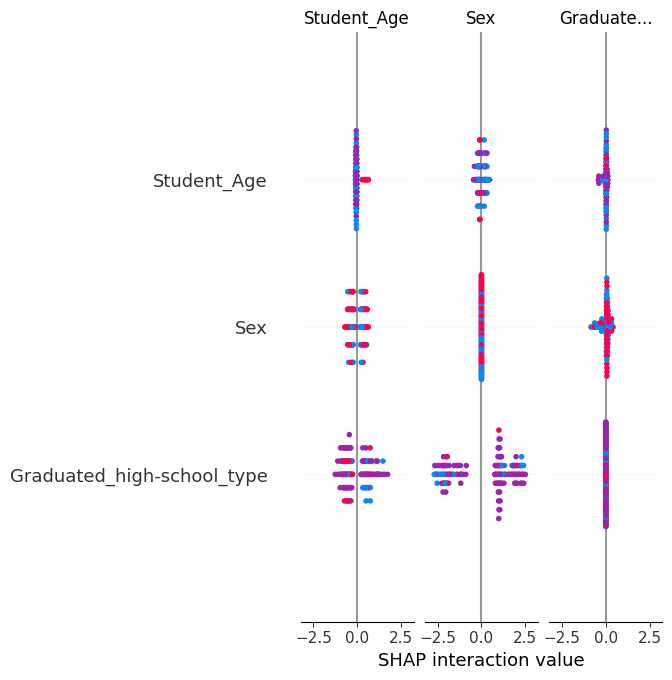

In [ ]:
#SHAP beeswarm plot
shap.summary_plot(
    shap_values,
    X
)